# 零售销售数据分析项目（Retail Sales Analysis）

> 求职练习项目 · 目标岗位：数据运营实习生

## 板块 1：项目简介

本项目基于一份公开的开源零售订单数据集（`Retail_Sales.csv`，共 2,000 条订单记录）进行练习，在复现原版项目基础 SQL 指标的基础上，自主拓展了 5 项运营分析（月度环比、用户复购、用户分层、品类客单价、品类毛利率）。

**项目定位**：这是一个「业务取数 + 运营分析」项目，不是建模项目。它重点证明求职者具备四种能力：

1. 会检查、校验数据（拿到数据先找"坑"）；
2. 会 SQL 取数（用 pandasql 完成指标计算）；
3. 理解运营核心指标（环比、复购、用户分层、客单价、毛利率）；
4. 能把数据结果翻译成可落地的业务建议。

**重要声明**：本项目为个人求职练习项目，数据集为公开练习数据，不涉及任何企业真实业务与隐私数据；所有分析结论只针对本练习数据集，不可直接套用于真实商业环境。


## 数据集字段说明

| 字段 | 含义 | 字段 | 含义 |
| --- | --- | --- | --- |
| transactions_id | 交易流水号（主键） | category | 商品品类（Clothing / Electronics / Beauty） |
| sale_date | 交易日期 | quantity | 购买件数 |
| sale_time | 交易时间 | price_per_unit | 商品单价 |
| customer_id | 客户 ID | cogs | 单件成本（cost of goods sold） |
| gender | 客户性别 | total_sale | 该笔订单销售额 |
| age | 客户年龄 | | |

> 注：原始 CSV 中第 8 列实际列名是 `quantiy`（拼写错误），会在数据清洗阶段统一修正为 `quantity`。


## 分析流程

1. **数据读取与探查**：读取 CSV，查看形状、字段类型、前 15 行样本、描述性统计、缺失值，并识别 sales=0 取消订单、负毛利订单等异常；
2. **数据清洗**：修正字段名拼写、规范时间格式、剔除缺失记录、过滤异常订单（sales ≤ 0）；
3. **基础指标复现**：复现原版 10 个 SQL 业务问题（并修正原版中与数据不符、边界重叠的问题）；
4. **自主拓展分析**：月度环比、用户复购、用户分层、品类客单价、品类毛利率，每项「SQL + 可视化 + 三段式解读」；
5. **结论与局限**：汇总业务结论，说明局限与后续优化方向。


In [3]:
%matplotlib inline

# ===== 1. 导入依赖 =====
import pandas as pd
import numpy as np
from pandasql import sqldf
import matplotlib.pyplot as plt

# ===== 2. matplotlib 中文设置（解决中文乱码、负号显示异常）=====
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'PingFang SC', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False   # 解决负号 '-' 显示为方块的问题

# ===== 3. pandasql 封装：让 SQL 能直接读到 notebook 里的 DataFrame =====
pysqldf = lambda q: sqldf(q, globals())


## 板块 2：数据读取、数据探查、数据清洗

> 这一步是面试官最看重、也最容易被新人忽略的一环：**拿到数据先别急着分析，先确认数据"干不干净、准不准确"。**


In [4]:
# 读取数据
df = pd.read_csv('Retail_Sales.csv')

# 1) 数据集形状：行数、列数
print('数据集形状（行, 列）：', df.shape)

# 2) 字段类型
print('\n字段类型：')
print(df.dtypes)


数据集形状（行, 列）： (2000, 11)

字段类型：
transactions_id      int64
sale_date              str
sale_time              str
customer_id          int64
gender                 str
age                float64
category               str
quantiy            float64
price_per_unit     float64
cogs               float64
total_sale         float64
dtype: object


**观察：**
- 数据集共 **2,000 行 × 11 列**，一行代表一笔订单明细。
- `sale_date`、`sale_time`、`gender`、`category` 被读成字符串（object）。
- `age`、`quantity`、`price_per_unit`、`cogs`、`total_sale` 本该是数值，却显示为 float（而非 int）——这通常是列里存在缺失值（NaN 会迫使整列升级为 float）的信号，下面逐一验证。


In [5]:
# 3) 前 15 行样本：肉眼校验字段取值是否正常
df.head(15)


,transactions_id,sale_date,sale_time,customer_id,gender,age,category,quantiy,price_per_unit,cogs,total_sale
0,180,2022-11-05,10:47:00,117,Male,41.0,Clothing,3.0,300.0,129.00,900.0
1,522,2022-07-09,11:00:00,52,Male,46.0,Beauty,3.0,500.0,145.00,1500.0
2,559,2022-12-12,10:48:00,5,Female,40.0,Clothing,4.0,300.0,84.00,1200.0
3,1180,2022-01-06,8:53:00,85,Male,41.0,Clothing,3.0,300.0,129.00,900.0
4,1522,2022-11-14,8:35:00,48,Male,46.0,Beauty,3.0,500.0,235.00,1500.0
5,1559,2022-08-20,7:40:00,49,Female,40.0,Clothing,4.0,300.0,144.00,1200.0
6,163,2022-10-31,9:38:00,144,Female,64.0,Clothing,3.0,50.0,23.00,150.0
7,303,2022-04-22,11:09:00,54,Male,19.0,Electronics,3.0,30.0,14.70,90.0
8,421,2022-04-08,8:43:00,66,Female,37.0,Clothing,3.0,500.0,235.00,1500.0
9,979,2022-05-18,10:18:00,6,Female,19.0,Beauty,1.0,25.0,10.50,25.0


**观察：**
- 第 8 列列名是 `quantiy`，是 `quantity`（数量）的拼写错误，需要重命名，否则后续写 SQL 容易踩坑。
- `sale_time` 存在两种写法：`10:47:00`（小时两位）与 `8:53:00`（小时一位、未补零）。直接按"前两位字符"取小时会出错，需要先统一格式。
- `total_sale` 恰好等于 `quantity × price_per_unit`（例如 3 × 300 = 900），金额逻辑自洽。


In [6]:
# 4) 缺失值统计
print('各字段缺失值数量：')
print(df.isnull().sum())
print('\n至少含一个缺失值的行数：', df.isnull().any(axis=1).sum())


各字段缺失值数量：
transactions_id     0
sale_date           0
sale_time           0
customer_id         0
gender              0
age                10
category            0
quantiy             3
price_per_unit      3
cogs                3
total_sale          3
dtype: int64

至少含一个缺失值的行数： 13


**观察（缺失值）：**
- 共 **13 行**存在缺失值：`age` 缺 10 个；`quantity / price_per_unit / cogs / total_sale` 各缺 3 个（这 3 个字段缺失的是同一批订单）。
- 金额/数量类字段缺失 = 该笔交易信息不完整，无法计入任何销售额指标，应删除；年龄缺失无法可靠推算，也一并删除（合计占比仅 0.65%，不影响结论）。
- 这也解释了为什么 `age`、`quantity` 等字段被读成 float——NaN 会迫使整列升级为浮点型。


In [7]:
# 5) 异常订单识别
# 5.1 取消订单：业务定义 total_sale = 0 的订单为取消订单，不属于有效成交
print('total_sale = 0 的行数：', (df['total_sale'] == 0).sum())
print('total_sale < 0 的行数：', (df['total_sale'] < 0).sum())
print('total_sale 最小值：', df['total_sale'].min())

# 5.2 主键唯一性
print('\ntransactions_id 重复数：', df['transactions_id'].duplicated().sum())

# 5.3 金额勾稽：total_sale 应等于 quantity * price_per_unit
print('total_sale 与 quantity*price_per_unit 不一致的行数：',
      ((df['quantiy'] * df['price_per_unit']) - df['total_sale']).abs().round(2).gt(0.01).sum())

# 5.4 负毛利订单：成本(cogs)高于售价(price_per_unit)，毛利为负
print('cogs > price_per_unit 的行数（负毛利订单）：', (df['cogs'] > df['price_per_unit']).sum())


total_sale = 0 的行数： 0
total_sale < 0 的行数： 0
total_sale 最小值： 25.0

transactions_id 重复数： 0
total_sale 与 quantity*price_per_unit 不一致的行数： 0
cogs > price_per_unit 的行数（负毛利订单）： 309


**观察（异常订单识别）：**
- **取消订单（sales=0）**：本数据集检查结果 `total_sale = 0` 和 `total_sale < 0` 均为 **0 行**（最小值 25 元），说明这份数据本身未包含取消订单；但为口径稳健、可复用，后续所有指标仍统一加 `total_sale > 0` 过滤。
- **主键唯一性**：`transactions_id` 无重复，可作为订单唯一标识。
- **金额勾稽**：所有 `total_sale` 均等于 `quantity × price_per_unit`，金额逻辑一致。
- **负毛利订单**：发现 **309 笔**订单 `cogs > price_per_unit`（成本高于售价，毛利为负），约占 15.6%。这可能是成本录入异常，也可能是"引流 / 清仓亏本卖"，会在拓展⑤毛利率分析中单独说明。


In [8]:
# 6) 数值字段描述性统计 + 分类字段分布 + 日期范围
df.describe().round(2)


,transactions_id,customer_id,age,quantiy,price_per_unit,cogs,total_sale
count,2000.00,2000.00,1990.00,1997.00,1997.00,1997.00,1997.00
mean,1000.50,66.34,41.34,2.51,180.12,95.02,456.54
std,577.49,44.94,13.67,1.13,189.69,121.90,560.10
min,1.00,1.00,18.00,1.00,25.00,6.25,25.00
25%,500.75,24.00,29.00,1.00,30.00,13.00,60.00
50%,1000.50,69.00,42.00,3.00,50.00,27.50,150.00
75%,1500.25,102.00,53.00,4.00,300.00,147.00,900.00
max,2000.00,155.00,64.00,4.00,500.00,620.00,2000.00


In [9]:
print('品类分布：')
print(df['category'].value_counts())
print('\n性别分布：')
print(df['gender'].value_counts())
print('\n日期范围：', df['sale_date'].min(), '~', df['sale_date'].max())


品类分布：
category
Clothing       702
Electronics    684
Beauty         614
Name: count, dtype: int64

性别分布：
gender
Female    1020
Male       980
Name: count, dtype: int64

日期范围： 2022-01-01 ~ 2023-12-31


**观察（取值范围）：**
- `quantity` 只取 1~4 件，`price_per_unit` 只有 25 / 30 / 50 / 300 / 500 五档，说明这是一份标准化定价的数据。
- `age` 覆盖 18~64 岁，客群较广；`total_sale` 范围 25~2,000 元。
- 品类分布：Clothing 702、Electronics 684、Beauty 614，三品类较均衡；性别：女 1,020、男 980，基本均衡。
- 日期范围 2022-01-01 ~ 2023-12-31，覆盖两个完整年度，适合做同比、环比。


## 数据清洗逻辑（业务视角）

基于上面的探查，确定以下清洗规则：

| 问题 | 处理方式 | 理由（业务视角） |
| --- | --- | --- |
| 列名 `quantiy` 拼写错误 | 重命名为 `quantity` | 统一字段名，避免取数时引用错误 |
| `age` 有 10 条缺失 | 删除该行 | 年龄是用户画像关键字段，无法可靠推算；占比仅 0.5%，直接剔除不影响结论 |
| `quantity / price_per_unit / cogs / total_sale` 各 3 条缺失 | 删除该行 | 金额类字段缺失 = 交易信息不完整，不能计入任何销售额指标 |
| `sale_time` 小时位未补零 | 统一补零为 `HH:MM:SS` | 保证按时段（早/中/晚）取小时不出错 |
| `age`、`quantity` 为 float | 转回 int | 它们是计数型字段，缺失值清除后应还原为整数 |
| 取消订单（sales ≤ 0） | 加 `total_sale > 0` 过滤 | sales ≤ 0 不属于有效成交，不纳入任何指标（本数据虽未发现，仍保留防线） |


In [10]:
# ===== 执行清洗，产出统一的干净口径 retail_clean =====
retail_clean = df.copy()

# 1) 修正列名拼写
retail_clean.rename(columns={'quantiy': 'quantity'}, inplace=True)

# 2) 统一时间格式：小时位补零（8:53:00 -> 08:53:00）
retail_clean['sale_time'] = retail_clean['sale_time'].str.zfill(8)

# 3) 剔除含缺失值的行
retail_clean = retail_clean.dropna()

# 4) 过滤取消订单（sales<=0），固化为后续所有指标口径
retail_clean = retail_clean[retail_clean['total_sale'] > 0]

# 5) 计数型字段还原为整数
retail_clean['age'] = retail_clean['age'].astype(int)
retail_clean['quantity'] = retail_clean['quantity'].astype(int)

print('清洗前：', df.shape, '  ->  清洗后：', retail_clean.shape)
print('\n清洗后各字段类型：')
print(retail_clean.dtypes)


清洗前： (2000, 11)   ->  清洗后： (1987, 11)

清洗后各字段类型：
transactions_id      int64
sale_date              str
sale_time              str
customer_id          int64
gender                 str
age                  int64
category               str
quantity             int64
price_per_unit     float64
cogs               float64
total_sale         float64
dtype: object


> 说明：`sale_date` 特意保留为 `YYYY-MM-DD` 字符串而非 datetime。原因：pandasql 底层通过 `to_sql` 写入 SQLite 时，datetime 会被转成 `'2022-11-05 00:00:00'` 这种带时间戳尾巴的文本，直接 `= '2022-11-05'` 比较会漏数据；保留标准日期字符串即可直接比较，也兼容 SQLite 的 `substr`/`strftime` 日期函数。


**清洗小结：**
- 原始 2,000 行 → 清洗后 **1,987 行**（剔除 13 行含缺失值的记录；未发现需额外过滤的取消订单）。
- 数据质量总体较好，主要问题是：1 个列名拼写错误、13 行金额/年龄缺失、时间字段格式不统一。
- 后续所有分析统一基于 `retail_clean`，口径一致。


## 板块 3：基础指标复现（原版指标）

本板块复现原版项目的 10 个 SQL 业务问题。原版使用 MySQL 语法（`EXTRACT`、`RANK() OVER` 等），这里统一改写为 pandasql（SQLite）语法，并对原版中明显有误或含糊的地方做了修正说明。

每一条 SQL 上方都写明**这条查询要解决的业务问题**，执行后给出结果表与简短解读。


In [11]:
# 【Q1 业务问题】2022-11-05 当天成交了哪些订单？用于日常经营日报与单日业绩核对。
q1 = pysqldf("""
SELECT *
FROM retail_clean
WHERE sale_date = '2022-11-05';
""")
q1


,transactions_id,sale_date,sale_time,customer_id,gender,age,category,quantity,price_per_unit,cogs,total_sale
0,180,2022-11-05,10:47:00,117,Male,41,Clothing,3,300.0,129.00,900.0
1,240,2022-11-05,11:49:00,95,Female,23,Beauty,1,300.0,123.00,300.0
2,1256,2022-11-05,09:58:00,29,Male,23,Clothing,2,500.0,190.00,1000.0
3,1587,2022-11-05,20:06:00,140,Female,40,Beauty,4,300.0,105.00,1200.0
4,1819,2022-11-05,20:44:00,83,Female,35,Beauty,2,50.0,13.50,100.0
5,943,2022-11-05,19:29:00,90,Female,57,Clothing,4,300.0,318.00,1200.0
6,1896,2022-11-05,20:19:00,87,Female,30,Electronics,2,25.0,30.75,50.0
7,1137,2022-11-05,22:34:00,104,Male,46,Beauty,2,500.0,145.00,1000.0
8,856,2022-11-05,17:43:00,102,Male,54,Electronics,4,30.0,9.30,120.0
9,214,2022-11-05,16:31:00,53,Male,20,Beauty,2,30.0,8.10,60.0


**结果解读**：2022-11-05 当天共成交 11 笔，合计 6,830 元。这是一张"单日流水"级别的明细，可用于核对某天是否异常（如突然无成交、或有异常大单）。


In [12]:
# 【Q2 业务问题】2022 年 11 月 Clothing 品类里，单笔买满 4 件（本数据件数上限）的大单有哪些？
# 用于识别该品类的批量采购需求，判断是否存在"批发式"购买。
q2 = pysqldf("""
SELECT *
FROM retail_clean
WHERE category = 'Clothing'
  AND quantity = 4
  AND substr(sale_date, 1, 7) = '2022-11';
""")
q2


,transactions_id,sale_date,sale_time,customer_id,gender,age,category,quantity,price_per_unit,cogs,total_sale
0,1484,2022-11-23,09:29:00,22,Female,19,Clothing,4,300.0,147.0,1200.0
1,64,2022-11-15,06:34:00,7,Male,49,Clothing,4,25.0,8.5,100.0
2,284,2022-11-12,09:17:00,129,Male,43,Clothing,4,50.0,20.5,200.0
3,1885,2022-11-09,07:32:00,148,Female,52,Clothing,4,30.0,10.8,120.0
4,547,2022-11-14,07:36:00,3,Male,63,Clothing,4,500.0,250.0,2000.0
5,159,2022-11-10,21:30:00,42,Male,26,Clothing,4,50.0,23.5,200.0
6,699,2022-11-21,22:21:00,129,Female,37,Clothing,4,30.0,16.2,120.0
7,1259,2022-11-03,17:31:00,105,Female,45,Clothing,4,50.0,21.0,200.0
8,146,2022-11-10,22:01:00,74,Male,38,Clothing,4,50.0,49.0,200.0
9,1476,2022-11-11,22:27:00,130,Female,27,Clothing,4,500.0,555.0,2000.0


**修正说明**：原版问题写的是 `quantity > 10`，但本数据 `quantity` 取值仅为 1~4，该条件会返回空结果，属于原版描述与数据实际不符；这里改为 `quantity = 4`（件数上限），业务含义等价于"该品类的大单"。

**结果解读**：2022 年 11 月 Clothing 品类共有 17 笔"满 4 件"的大单。这类订单是备货与库存预警的重点关注对象。


In [13]:
# 【Q3 业务问题】各商品品类的销售额和订单量分别是多少？用于判断哪个品类是收入主力，指导备货与运营资源分配。
q3 = pysqldf("""
SELECT category,
       COUNT(*)           AS order_count,
       SUM(total_sale)    AS net_sales
FROM retail_clean
GROUP BY category
ORDER BY net_sales DESC;
""")
q3


,category,order_count,net_sales
0,Electronics,678,311445.0
1,Clothing,698,309995.0
2,Beauty,611,286790.0


**结果解读**：三大品类销售额接近——Electronics 311,445 元、Clothing 309,995 元、Beauty 286,790 元，没有"一家独大"的品类，属于相对均衡的收入结构。


In [14]:
# 【Q4 业务问题】购买 Beauty 品类的客户平均年龄是多少？用于刻画该品类核心客群画像，指导选品与营销话术。
q4 = pysqldf("""
SELECT ROUND(AVG(age), 2) AS avg_age
FROM retail_clean
WHERE category = 'Beauty';
""")
q4


,avg_age
0,40.42


**结果解读**：Beauty 品类客户平均年龄约 40.4 岁，客群偏成熟。做该品类推广时，话术与素材可更贴近 30~50 岁人群的诉求。


In [15]:
# 【Q5 业务问题】单笔销售额超过 1000 元的高客单订单有多少、贡献多大？用于评估大单占比，判断是否依赖高客单成交。
q5 = pysqldf("""
SELECT COUNT(*)                                                        AS big_order_count,
       SUM(total_sale)                                                 AS big_order_sales,
       ROUND(SUM(total_sale) * 100.0
             / (SELECT SUM(total_sale) FROM retail_clean), 2)          AS sales_share_pct
FROM retail_clean
WHERE total_sale > 1000;
""")
q5


,big_order_count,big_order_sales,sales_share_pct
0,306,475600.0,52.37


**结果解读**：单笔超 1,000 元的订单共 306 笔，合计 475,600 元，**占总销售额 52.37%**。

**修正说明**：原版是 `SELECT *` 直接列出全部 306 行明细，信息密度低；这里改为"数量 + 金额 + 占比"的汇总口径，更贴合运营看板习惯。


In [16]:
# 【Q6 业务问题】不同性别客户在各品类的下单量分布如何？用于判断各品类的性别偏好，指导差异化投放。
q6 = pysqldf("""
SELECT gender,
       category,
       COUNT(*) AS order_count
FROM retail_clean
GROUP BY gender, category
ORDER BY gender, category;
""")
q6


,gender,category,order_count
0,Female,Beauty,330
1,Female,Clothing,347
2,Female,Electronics,335
3,Male,Beauty,281
4,Male,Clothing,351
5,Male,Electronics,343


**结果解读**：各品类的男女订单量差距都不大（如 Clothing：女 347 / 男 351），说明这份数据里性别对品类的偏好差异不明显，投放时不宜按性别做强区隔。


In [17]:
# 【Q7 业务问题】每年销售额（按平均单额）最高的月份是哪个月？用于识别销售旺季，规划促销节奏。
q7 = pysqldf("""
SELECT year,
       month,
       ROUND(avg_sale, 2) AS avg_sale
FROM (
    SELECT substr(sale_date, 1, 4) AS year,
           substr(sale_date, 6, 2) AS month,
           AVG(total_sale) AS avg_sale,
           RANK() OVER (PARTITION BY substr(sale_date, 1, 4)
                        ORDER BY AVG(total_sale) DESC) AS rnk
    FROM retail_clean
    GROUP BY year, month
)
WHERE rnk = 1
ORDER BY year;
""")
q7


,year,month,avg_sale
0,2022,07,541.34
1,2023,02,535.53


**结果解读**：按"月平均单额"口径，2022 年最好月份是 7 月（541.34 元）、2023 年是 2 月（535.53 元）。注意这与"月总销售额最高"是两回事（按总额口径 12 月最高），说明：**旺季靠"订单量大"，淡月靠"单均金额高"**，两种口径要分开看。


In [18]:
# 【Q8 业务问题】累计消费金额最高的 5 位客户是谁？用于识别高价值客户，评估头部客户对收入的贡献。
q8 = pysqldf("""
SELECT customer_id,
       SUM(total_sale) AS total_sales
FROM retail_clean
GROUP BY customer_id
ORDER BY total_sales DESC
LIMIT 5;
""")
q8


,customer_id,total_sales
0,3,38440.0
1,1,30750.0
2,5,30405.0
3,2,25295.0
4,4,23580.0


**结果解读**：Top 5 客户累计消费 2.3 万~3.8 万元，头部效应明显。这类客户适合做专属维护与防流失，具体分层在板块 4 展开。


In [19]:
# 【Q9 业务问题】每个品类各自有多少位不同客户购买过？用于衡量品类的客户覆盖广度，判断品类渗透率。
q9 = pysqldf("""
SELECT category,
       COUNT(DISTINCT customer_id) AS unique_customers
FROM retail_clean
GROUP BY category
ORDER BY unique_customers DESC;
""")
q9


,category,unique_customers
0,Clothing,149
1,Electronics,144
2,Beauty,141


**结果解读**：三品类覆盖的客户数非常接近（Clothing 149、Electronics 144、Beauty 141），说明各品类在客户群里都有较高的渗透，客户跨品类购买较普遍。


In [20]:
# 【Q10 业务问题】一天中早/中/晚三个时段的订单量分布如何？用于优化营业时段排班与客服人力安排。
q10 = pysqldf("""
SELECT CASE
           WHEN CAST(substr(sale_time, 1, 2) AS INTEGER) < 12 THEN 'Morning(早)'
           WHEN CAST(substr(sale_time, 1, 2) AS INTEGER) < 17 THEN 'Afternoon(中)'
           ELSE 'Evening(晚)'
       END  AS shift,
       COUNT(*) AS order_count
FROM retail_clean
GROUP BY shift
ORDER BY order_count DESC;
""")
q10


,shift,order_count
0,Evening(晚),1275
1,Morning(早),548
2,Afternoon(中),164


**结果解读**：晚间订单最多（1,275 单），其次早晨（548 单），下午最少（164 单）。排班和客服人力应重点覆盖晚间高峰。

**修正说明**：原版时段边界是 `Morning ≤12` 且 `Afternoon 12~17`，12 点同时落在两个区间，存在重叠；这里统一为 `早 <12`、`中 12~16`、`晚 ≥17`，边界互斥。


## 板块 4：自主拓展运营指标分析【环比、复购、用户分层、品类客单价、品类毛利率】

本板块为**自主拓展部分（核心亮点）**，在原版 10 个基础指标之上，围绕运营同学日常最关心的 5 个问题做深挖（第 5 项"毛利率"为在原版基础上的新增）。

每个拓展点统一采用：**pandasql 取数 → matplotlib 可视化 → 三段式解读（现象 / 合理猜想 / 落地运营建议）**。


### 拓展 ① 月度销售额环比分析

**指标口径**：
- 月度销售额 = 当月 `total_sale` 之和；
- 环比增长率 = (本月销售额 − 上月销售额) / 上月销售额 × 100%。
- 目的：看销售趋势与季节性，找出起量/回落的关键节点。


In [21]:
# 【拓展①业务问题】每个月的销售额与订单量是多少？为计算环比、识别销售旺季打底。
monthly_sales = pysqldf("""
SELECT substr(sale_date, 1, 7) AS year_month,
       SUM(total_sale)         AS monthly_sales,
       COUNT(*)                AS order_count
FROM retail_clean
GROUP BY year_month
ORDER BY year_month;
""")
monthly_sales


,year_month,monthly_sales,order_count
0,2022-01,22635.0,57
1,2022-02,16110.0,44
2,2022-03,23455.0,45
3,2022-04,28535.0,57
4,2022-05,24480.0,51
5,2022-06,20700.0,43
6,2022-07,22195.0,41
7,2022-08,21075.0,54
8,2022-09,61620.0,127
9,2022-10,67735.0,145


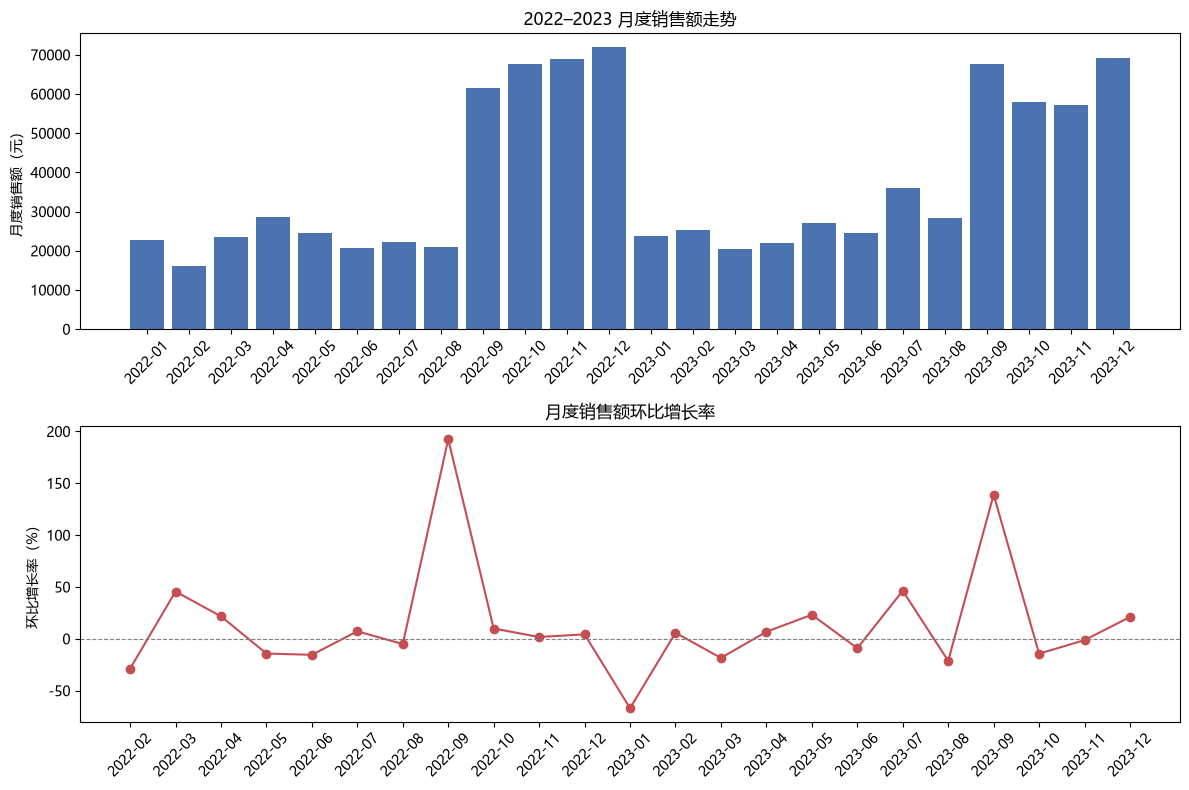

In [22]:
# 计算环比增长率（首月无上月，为 NaN）
monthly_sales['mom_pct'] = monthly_sales['monthly_sales'].pct_change() * 100

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# 上图：月度销售额柱状图
axes[0].bar(monthly_sales['year_month'], monthly_sales['monthly_sales'], color='#4C72B0')
axes[0].set_ylabel('月度销售额（元）')
axes[0].set_title('2022–2023 月度销售额走势')
axes[0].tick_params(axis='x', rotation=45)

# 下图：月度环比增长率折线图（去掉首月 NaN）
mom = monthly_sales.dropna(subset=['mom_pct'])
axes[1].plot(mom['year_month'], mom['mom_pct'], marker='o', color='#C44E52')
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[1].set_ylabel('环比增长率（%）')
axes[1].set_title('月度销售额环比增长率')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('img/monthly_sales_mom.png', dpi=150, bbox_inches='tight')
plt.show()


> 📷 **图片占位**：运行上方代码后，图表自动保存到 `img/monthly_sales_mom.png`，请在此处插入该图。

**（1）现象**：
- 每年 1–8 月销售额在 1.6 万~3.6 万之间低位波动，订单量约 41~60 单；每年 9 月销售额突然跳升至 6 万以上（2022-09 约 6.16 万、2023-09 约 6.76 万），订单量翻倍到 127~146 单，此后 10–12 月保持高位，12 月达到全年峰值。
- 环比折线最醒目的是两个"尖峰"：2022-09 环比 **+192.4%**、2023-09 环比 **+139.0%**；以及每年 1 月的大幅回落（2023-01 环比 **-66.9%**），呈明显的"9 月起量 → 12 月冲顶 → 1 月回落"节奏。

**（2）合理猜想**：
- 9 月陡增可能对应"金九银十"促销启动；12 月冲顶符合年末大促、节日送礼的消费习惯；1 月环比暴跌是促销透支后的自然回落，叠加订单样本量骤降（从 156 单降到 60 单）。

**（3）落地运营建议**：
- 把备货、物流、客服人力在 **9 月初**就前置到位，而不是 12 月才临时加码；
- 针对 1 月深谷，用"返场 / 新年焕新"小活动承接节后余量，避免全年最深的回落；
- 提示：1–8 月订单样本明显偏少，环比波动大，做决策前要结合真实订单量确认，不能只看百分比。


### 拓展 ② 用户复购分析

**指标口径**：
- 复购深度 = 每位客户的累计购买次数；
- 分层：轻复购（2–4 次）/ 中复购（5–9 次）/ 深复购（≥10 次）；
- 观察各层人数、订单量与销售额贡献，衡量用户粘性。


In [23]:
# 【拓展②业务问题】按购买次数把用户分成轻/中/深三层复购，看各层人数与销售额贡献，衡量用户粘性分层。
repurchase = pysqldf("""
WITH user_orders AS (
    SELECT customer_id, COUNT(*) AS order_cnt
    FROM retail_clean
    GROUP BY customer_id
),
user_tier AS (
    SELECT customer_id,
           CASE
               WHEN order_cnt >= 10 THEN '深复购(>=10次)'
               WHEN order_cnt >= 5  THEN '中复购(5-9次)'
               ELSE '轻复购(2-4次)'
           END AS repurchase_tier
    FROM user_orders
)
SELECT ut.repurchase_tier,
       COUNT(DISTINCT ut.customer_id) AS customer_count,
       COUNT(*)                       AS order_count,
       SUM(r.total_sale)              AS revenue
FROM retail_clean r
JOIN user_tier ut ON r.customer_id = ut.customer_id
GROUP BY ut.repurchase_tier
ORDER BY customer_count DESC;
""")
repurchase


,repurchase_tier,customer_count,order_count,revenue
0,深复购(>=10次),88,1557,710705.0
1,中复购(5-9次),55,392,174995.0
2,轻复购(2-4次),12,38,22530.0


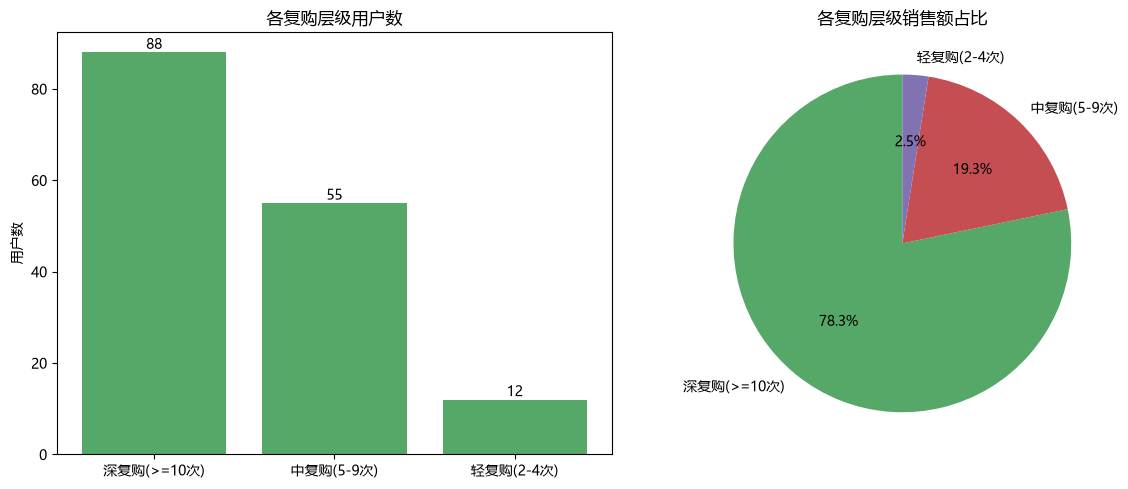

In [24]:
repurchase['revenue_share'] = repurchase['revenue'] / repurchase['revenue'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 左：各层用户数柱状图
bars = axes[0].bar(repurchase['repurchase_tier'], repurchase['customer_count'], color='#55A868')
axes[0].set_title('各复购层级用户数')
axes[0].set_ylabel('用户数')
for b, v in zip(bars, repurchase['customer_count']):
    axes[0].text(b.get_x() + b.get_width()/2, v, int(v), ha='center', va='bottom')

# 右：各层销售额占比饼图
axes[1].pie(repurchase['revenue'], labels=repurchase['repurchase_tier'],
            autopct='%1.1f%%', startangle=90, colors=['#55A868', '#C44E52', '#8172B2'])
axes[1].set_title('各复购层级销售额占比')

plt.tight_layout()
plt.savefig('img/repurchase_analysis.png', dpi=150, bbox_inches='tight')
plt.show()


> 📷 **图片占位**：运行上方代码后，图表自动保存到 `img/repurchase_analysis.png`，请在此处插入该图。

**（1）现象**：
- 155 位客户购买次数都 ≥2 次，平均每位客户购买 **12.8 次**，这是一份"老客/熟客"特征明显的数据。
- 深复购用户（≥10 次）88 人，占客户数 57%，却贡献了 **78.3%** 的销售额（约 71.1 万）；中复购 55 人占 19.3%；轻复购仅 12 人占 2.5%。少数高频用户撑起绝大部分收入。

**（2）合理猜想**：
- 客户结构高度向"高频老客"集中，符合典型的"二八分布"；也可能该数据集只保留了持续消费的活跃用户，缺少一次性流失用户样本。

**（3）落地运营建议**：
- 给 88 位深复购用户建"核心会员池"，配会员权益/积分/专属价，目标是稳住购买频次、防流失；
- 重点运营"中复购（5–9 次）"这一层——他们已养成习惯又有提升空间，用"满 N 次送赠品"的阶梯激励向上引导；
- 轻复购仅 12 人，先分析其品类偏好，再决定做交叉推荐还是放弃投入。


### 拓展 ③ 用户消费分层

**指标口径**：
- 用户价值 = 该客户累计消费金额（sum of total_sale）；
- 用 `NTILE(5)` 把客户按消费额五等分：高价值（前 20%）、中价值（中间 60%）、低价值（后 20%）；
- 观察各层人数与收入贡献，定位核心用户群。


In [25]:
# 【拓展③业务问题】按累计消费金额把用户分成高/中/低三层价值，看各层人数与收入贡献，定位核心用户群。
value_tier = pysqldf("""
WITH user_spend AS (
    SELECT customer_id, SUM(total_sale) AS total_spend
    FROM retail_clean
    GROUP BY customer_id
),
user_tier AS (
    SELECT customer_id, NTILE(5) OVER (ORDER BY total_spend) AS ntile
    FROM user_spend
)
SELECT CASE
           WHEN ntile = 5 THEN '高价值(前20%)'
           WHEN ntile = 1 THEN '低价值(后20%)'
           ELSE '中价值(20%-80%)'
       END   AS value_tier,
       COUNT(*)            AS customer_count,
       SUM(total_spend)    AS revenue
FROM user_tier ut
JOIN user_spend us ON ut.customer_id = us.customer_id
GROUP BY value_tier
ORDER BY CASE value_tier
             WHEN '高价值(前20%)' THEN 1
             WHEN '中价值(20%-80%)' THEN 2
             ELSE 3
         END;
""")
value_tier


,value_tier,customer_count,revenue
0,高价值(前20%),31,406885.0
1,中价值(20%-80%),93,449595.0
2,低价值(后20%),31,51750.0


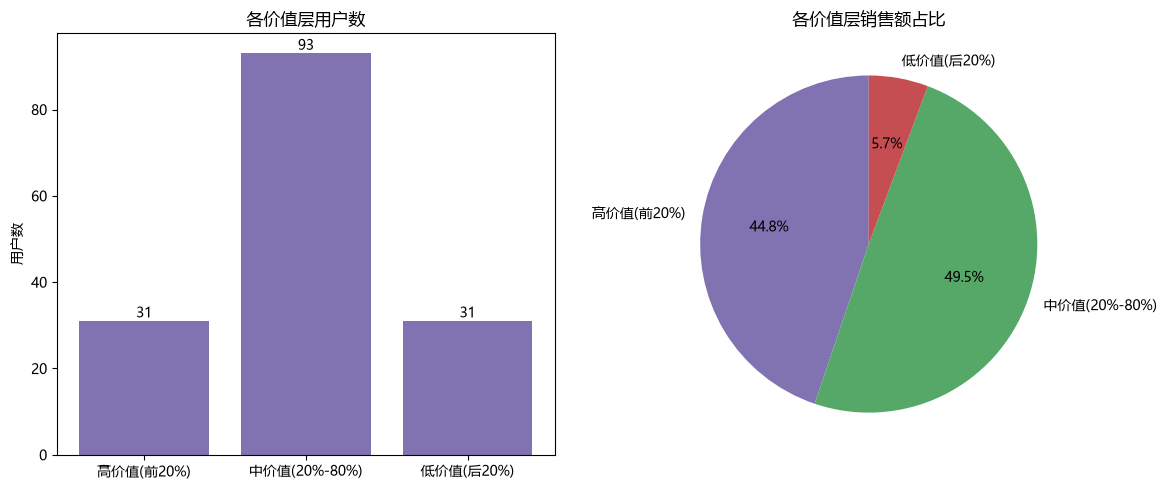

In [26]:
value_tier['revenue_share'] = value_tier['revenue'] / value_tier['revenue'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 左：各层用户数柱状图
bars = axes[0].bar(value_tier['value_tier'], value_tier['customer_count'], color='#8172B2')
axes[0].set_title('各价值层用户数')
axes[0].set_ylabel('用户数')
for b, v in zip(bars, value_tier['customer_count']):
    axes[0].text(b.get_x() + b.get_width()/2, v, int(v), ha='center', va='bottom')

# 右：各层销售额占比饼图
axes[1].pie(value_tier['revenue'], labels=value_tier['value_tier'],
            autopct='%1.1f%%', startangle=90, colors=['#8172B2', '#55A868', '#C44E52'])
axes[1].set_title('各价值层销售额占比')

plt.tight_layout()
plt.savefig('img/customer_value_tier.png', dpi=150, bbox_inches='tight')
plt.show()


> 📷 **图片占位**：运行上方代码后，图表自动保存到 `img/customer_value_tier.png`，请在此处插入该图。

**（1）现象**：
- 高价值用户（前 20%，31 人）贡献 **44.8%** 的销售额（约 40.7 万），人均消费约 1.3 万；中价值 93 人贡献 49.5%；低价值（后 20%，31 人）只贡献 **5.7%**（约 5.2 万）。
- 头部 20% 客户贡献近一半收入，尾部 20% 客户贡献不足 6%，收入高度依赖头部用户。

**（2）合理猜想**：
- 头部用户消费能力或购买频次显著更高，可能是批发型、礼品采购型或家庭集中采购型客户；
- 尾部用户贡献极小，可能是低频、低单价的尝鲜型或价格敏感型用户。

**（3）落地运营建议**：
- 对高价值 31 人提供一对一/专属客服、新品优先体验、大额满减，重点是"留存 + 提升客单"，防止被竞品挖走；
- 对占比最大的中价值 93 人做"向上爬升"运营：设置消费阶梯（如累计满 1 万解锁更高折扣），引导向高价值迁移；
- 对低价值 31 人不盲目补贴，先用低价引流款测试其价格弹性，再决定唤醒还是放弃。


### 拓展 ④ 不同品类客单价对比

**指标口径**：
- 客单价（AOV，Average Order Value）= 品类销售额 / 品类订单数；
- 含义：该品类平均每笔订单贡献多少收入，反映单价结构与连带销售能力。


In [27]:
# 【拓展④业务问题】各品类的客单价（单均销售额）分别是多少？用于对比品类单价结构，指导定价与连带销售。
aov = pysqldf("""
SELECT category,
       COUNT(*)                                AS order_count,
       SUM(total_sale)                         AS revenue,
       ROUND(SUM(total_sale) / COUNT(*), 2)    AS aov
FROM retail_clean
GROUP BY category
ORDER BY aov DESC;
""")
aov


,category,order_count,revenue,aov
0,Beauty,611,286790.0,469.38
1,Electronics,678,311445.0,459.36
2,Clothing,698,309995.0,444.12


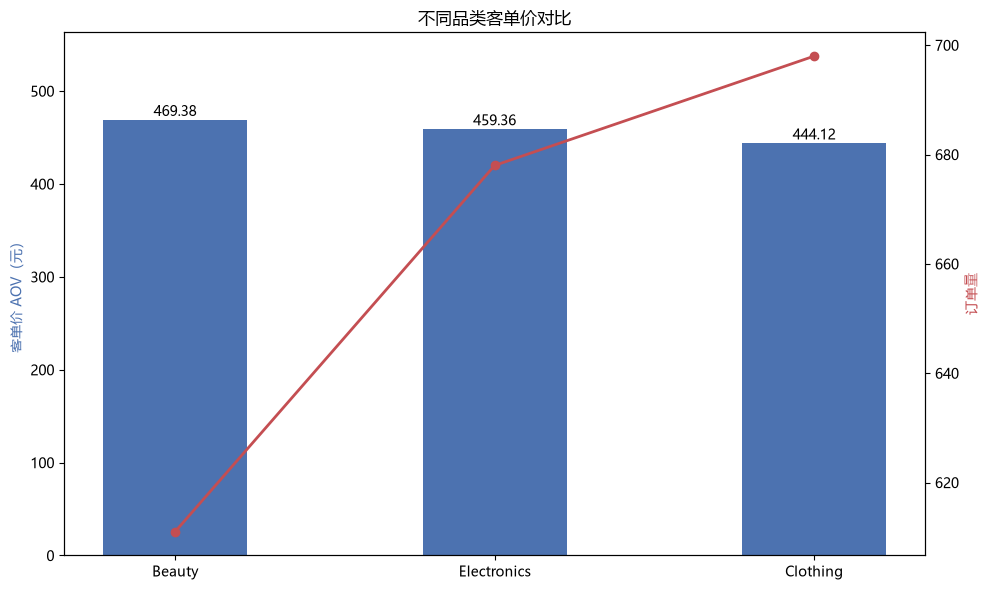

In [28]:
fig, ax1 = plt.subplots(figsize=(10, 6))

bars = ax1.bar(aov['category'], aov['aov'], color='#4C72B0', width=0.45)
ax1.set_ylabel('客单价 AOV（元）', color='#4C72B0')
ax1.set_title('不同品类客单价对比')
ax1.set_ylim(0, aov['aov'].max() * 1.2)
for b, v in zip(bars, aov['aov']):
    ax1.text(b.get_x() + b.get_width()/2, v, f'{v:.2f}', ha='center', va='bottom')

# 次坐标轴：订单量
ax2 = ax1.twinx()
ax2.plot(aov['category'], aov['order_count'], marker='o', color='#C44E52', linewidth=2)
ax2.set_ylabel('订单量', color='#C44E52')

plt.tight_layout()
plt.savefig('img/category_aov.png', dpi=150, bbox_inches='tight')
plt.show()


> 📷 **图片占位**：运行上方代码后，图表自动保存到 `img/category_aov.png`，请在此处插入该图。

**（1）现象**：
- 三品类客单价都在 444~470 元：Beauty 最高 **469.38 元**、Electronics 459.36 元、Clothing 最低 **444.12 元**，整体客单价约 457 元。
- 订单量上 Clothing 最多（698 单）、Electronics 次之（678 单）、Beauty 最少（611 单），但 Beauty 客单价反而最高。

**（2）合理猜想**：
- Beauty 更偏"高单价、低频"，Clothing 更偏"高频、低单价"，Electronics 居中；
- 三品类客单价差距不大（最大差值仅约 25 元），说明整体价格带没有拉开明显差异。

**（3）落地运营建议**：
- 想提整体客单价，优先在 Beauty 做"套装捆绑 / 连带销售"，它的单价基础最好、提升空间最大；
- Clothing 靠"多件优惠 / 满减"提升每单件数（当前平均 2.55 件），把 444 元的客单价往上抬；
- Electronics 订单量大，适合做引流走量品类，再通过"配件搭配 / 以旧换新"提升连带率。


### 拓展 ⑤ 不同品类毛利率对比（新增）

**指标口径**：
- 毛利 = `total_sale − cogs × quantity`（销售额减去成本）；
- 毛利率 = 毛利 / 销售额 × 100%。
- 目的：从"只看收入"升级到"看赚钱效率"，找出真正赚钱的品类。


In [29]:
# 【拓展⑤业务问题】各品类的毛利率分别是多少？哪个品类"又赚钱又省成本"？用于指导品类经营策略。
margin = pysqldf("""
SELECT category,
       SUM(total_sale)                                          AS revenue,
       SUM(total_sale - cogs * quantity)                        AS gross_profit,
       ROUND(SUM(total_sale - cogs * quantity) * 100.0
             / SUM(total_sale), 2)                              AS gross_margin_pct
FROM retail_clean
GROUP BY category
ORDER BY gross_margin_pct DESC;
""")
margin


,category,revenue,gross_profit,gross_margin_pct
0,Beauty,286790.0,137441.80,47.92
1,Clothing,309995.0,143236.30,46.21
2,Electronics,311445.0,140690.85,45.17


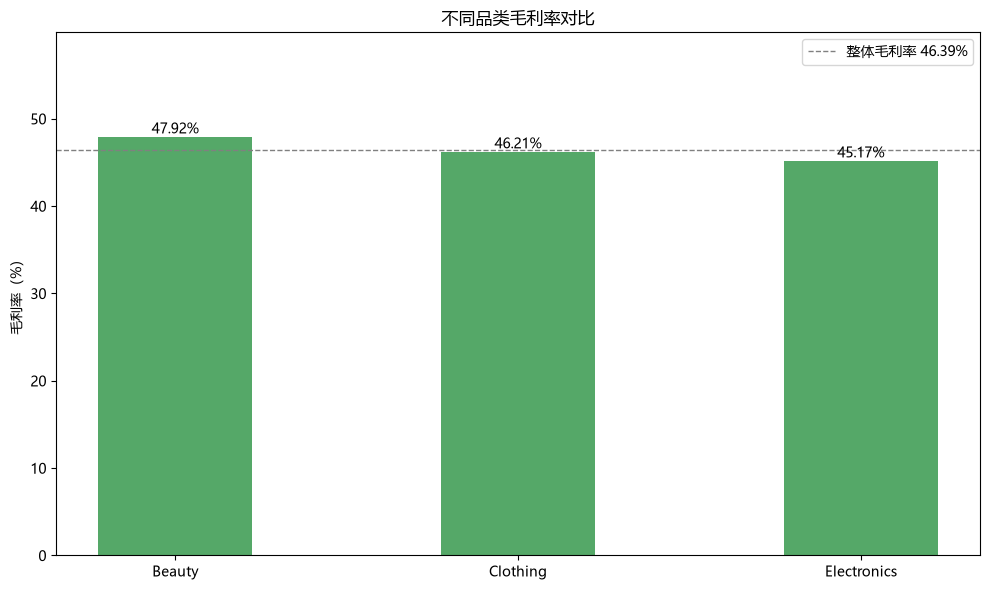

In [30]:
overall_margin = margin['gross_profit'].sum() / margin['revenue'].sum() * 100

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(margin['category'], margin['gross_margin_pct'], color='#55A868', width=0.45)
ax.axhline(overall_margin, color='gray', linestyle='--', linewidth=1,
           label=f'整体毛利率 {overall_margin:.2f}%')
ax.set_ylabel('毛利率（%）')
ax.set_title('不同品类毛利率对比')
ax.set_ylim(0, margin['gross_margin_pct'].max() * 1.25)
for b, v in zip(bars, margin['gross_margin_pct']):
    ax.text(b.get_x() + b.get_width()/2, v, f'{v:.2f}%', ha='center', va='bottom')
ax.legend()

plt.tight_layout()
plt.savefig('img/category_gross_margin.png', dpi=150, bbox_inches='tight')
plt.show()


> 📷 **图片占位**：运行上方代码后，图表自动保存到 `img/category_gross_margin.png`，请在此处插入该图。

**（1）现象**：
- 三品类毛利率在 45.17%~47.92%，整体 **46.39%**；Beauty 最高（47.92%）、Clothing 次之（46.21%）、Electronics 最低（45.17%）。
- 结合拓展④看：Beauty 是"客单价最高 + 毛利率最高"的双高品类；而收入最高的 Electronics，毛利率反而最低——**卖得最多的品类，赚钱效率最低**。

**（2）合理猜想**：
- Electronics 毛利率低，可能是它在承担"引流/走量"角色，用低毛利换销量规模；Beauty 高毛利来自品牌溢价或更低的成本结构。

**（3）落地运营建议**：
- 做 GMV/利润增长时优先推 Beauty（双高），做拉新、冲销量时用 Electronics（走量）；
- Electronics 要盯成本端：通过供应商议价、组合销售（配件搭售）把毛利往上抬；
- 针对探查中发现的 **309 笔负毛利订单**（cogs > 售价），先判断是成本录入异常还是清仓/引流策略：若为异常要修正数据口径，若为策略要评估亏损换来的拉新/清库存是否划算。


## 板块 5：综合业务结论汇总


### 核心业务发现（仅针对本练习数据集）

1. **整体规模**：有效订单 1,987 笔，总销售额 908,230 元，155 位客户，整体客单价约 457 元，平均每单 2.51 件。

2. **品类结构均衡**：Electronics（311,445 元）、Clothing（309,995 元）、Beauty（286,790 元）三品类收入接近，无"一家独大"。

3. **明显的季节节奏**：每年 9 月起量、12 月冲顶、1 月回落（2022-09 环比 +192.4%、2023-01 环比 -66.9%），运营资源应前置到 9 月。

4. **收入高度依赖头部与高频用户**：
   - 深复购用户（≥10 次，88 人）贡献 78.3% 销售额；
   - 高价值用户（前 20%，31 人）贡献 44.8% 销售额，呈典型"二八分布"。

5. **赚钱效率与收入规模不匹配**：整体毛利率 46.39%；Beauty 客单价、毛利率双高（469.38 元 / 47.92%），Electronics 收入最高但毛利率最低（45.17%），另有约 15.6% 的负毛利订单需排查。

6. **时段集中**：晚间订单占绝对主力（1,275 单），下午最少（164 单），排班应向晚间倾斜。

> **一句话总结**：这是一份"老客高频、三品类均衡、季节性强、晚间为主、收入与利润错位"的零售订单数据，运营重心应放在**老客留存与向上提升、9–12 月旺季前置、晚间履约能力、高毛利品类倾斜**上。


## 板块 6：项目局限与后续优化方向


### 项目局限性（诚实说明）

1. **数据为公开练习数据**：客户行为、价格带、时间分布都是模拟/构造的，结论只用于方法论演示，**不能直接套用到真实商业环境**。
2. **无商品、渠道、促销字段**：无法拆解"哪个单品/哪个渠道/哪场活动"带来增长，业务归因能力受限。
3. **时间粒度有限**：`sale_time` 只到小时，且 1–8 月样本量明显偏少，环比数字波动大。
4. **无真实复购周期字段**：复购分析只能按"累计次数"近似，无法精确到"多久回来买一次"。

### 后续优化方向

1. 引入 **RFM 模型**（最近一次消费 / 频次 / 金额）做更精细的用户分层，但仍属于取数分析，不涉及复杂建模；
2. 深化**成本分析**：排查 309 笔负毛利订单（cogs > 售价）是录入异常还是经营策略，并把毛利细化到单品级；
3. 增加**商品级、周维度**的向下钻取，定位到具体 SKU 与促销节奏；
4. 若拿到真实数据，可加入 A/B 实验、漏斗转化等运营专项分析。
